# Законы распределения дискретных случайных величин
Для каждого из четырёх законов (биномиальный, Пуассона, геометрический, гипергеометрический) сформулируем собственную задачу, составим закон распределения случайной величины $X$, найдём $M(X)$, $D(X)$, $\sigma(X)$, $Mo(X)$ и построим многоугольник распределения.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson, geom, hypergeom

pd.options.display.float_format = '{:.4f}'.format
%matplotlib inline

Моду будем искать как значение (значения) $x$ с наибольшей вероятностью, а многоугольник распределения - строить одной и той же функцией (мода отмечена красным).

In [18]:
def polygon(X, probabilities, mode, xlabel, title):
    plt.figure(figsize=(7, 3.5))
    plt.plot(X, probabilities, '-o', color='BLUE', ms=6, label='Многоугольник распределения')
    plt.plot(mode, probabilities[np.isin(X, mode)], 'o', color='RED', ms=10, label='Мода')
    plt.xticks(X)
    plt.xlabel(xlabel)
    plt.ylabel('P(X = k)')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 1. Биномиальный закон распределения
---
>**Условие.** Почтовый фильтр ошибочно отправляет каждое важное письмо в папку «Спам» независимо от остальных с вероятностью $0.3$. Студент ждёт $8$ важных писем от деканата. Случайная величина $X$ - число писем, которые попали в спам.

**Решение.** Письма независимы, для каждого «успех» (письмо попало в спам) наступает с вероятностью $p = 0.3$, число испытаний $n = 8$. Значит:

$$P(X = k) = C_{8}^k \cdot 0.3^k \cdot 0.7^{8 - k}.$$

In [19]:
n, p = 8, 0.3
X = np.arange(0, n + 1)

binom_dist = binom(n, p)
probabilities = binom_dist.pmf(X)

print(f"Сумма вероятностей: {probabilities.sum():.4f}")
pd.DataFrame(probabilities.reshape(1, -1), columns=X, index=['p'])

Сумма вероятностей: 1.0000


,0,1,2,3,4,5,6,7,8
p,0.0576,0.1977,0.2965,0.2541,0.1361,0.0467,0.0100,0.0012,0.0001


In [20]:
M = n * p
D = n * p * (1 - p)
mode_b = X[np.isclose(probabilities, probabilities.max())].tolist()

print(f"Математическое ожидание: M(X) = n*p = {M:.4f}")
print(f"Дисперсия: D(X) = n*p*q = {D:.4f}")
print(f"Среднее квадратическое отклонение: σ(X) = {np.sqrt(D):.4f}")
print(f"Мода: Mo(X) = {mode_b}  (по формуле [(n+1)p] = {int((n + 1) * p)})")
print(f"\nПроверка через scipy: M = {binom_dist.mean():.4f}, D = {binom_dist.var():.4f}, σ = {binom_dist.std():.4f}")

Математическое ожидание: M(X) = n*p = 2.4000
Дисперсия: D(X) = n*p*q = 1.6800
Среднее квадратическое отклонение: σ(X) = 1.2961
Мода: Mo(X) = [2]  (по формуле [(n+1)p] = 2)

Проверка через scipy: M = 2.4000, D = 1.6800, σ = 1.2961


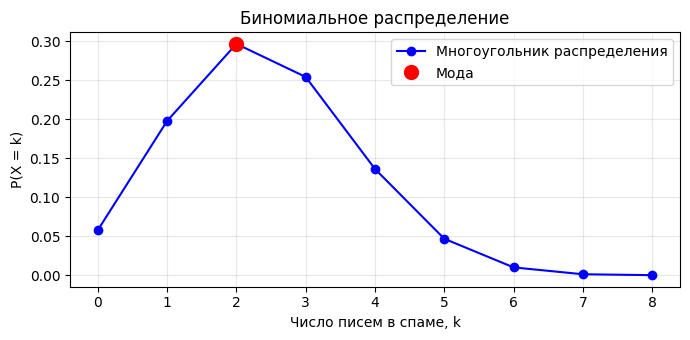

In [21]:
polygon(X, probabilities, mode_b, 'Число писем в спаме, k', 'Биномиальное распределение')

## 2. Закон распределения Пуассона
---
>**Условие.** Астроном-любитель наблюдает за ночным небом. В среднем за час он замечает $6$ метеоров, при этом метеоры появляются независимо друг от друга. Случайная величина $X$ - число метеоров, замеченных за $30$ минут наблюдения.

**Решение.** Редкие независимые события, происходящие с постоянной средней интенсивностью, подчиняются закону Пуассона. За $30$ минут в среднем наблюдается $\lambda = 6 \cdot 0.5 = 3$ метеора, поэтому:

$$P(X = k) = \frac{3^k}{k!} e^{-3}.$$

Значений бесконечно много, поэтому в таблицу запишем значения $k = 0, \dots, 10$, а вероятность остальных найдём отдельно.

In [32]:
lmb = 6 * 0.5
X = np.arange(0, 11)

poisson_dist = poisson(lmb)
probabilities = poisson_dist.pmf(X)

print(f"Сумма вероятностей в таблице: {probabilities.sum():.4f}")
print(f"Вероятность остальных значений P(X > 10) = {poisson_dist.sf(10):.4f}")
pd.DataFrame(probabilities.reshape(1, -1), columns=X, index=['p'])

Сумма вероятностей в таблице: 0.9997
Вероятность остальных значений P(X > 10) = 0.0003


,0,1,2,3,4,5,6,7,8,9,10
p,0.0498,0.1494,0.2240,0.2240,0.1680,0.1008,0.0504,0.0216,0.0081,0.0027,0.0008


In [35]:
mode_p = X[np.isclose(probabilities, probabilities.max())].tolist()

print(f"Математическое ожидание: M(X) = λ = {lmb:.4f}")
print(f"Дисперсия: D(X) = λ = {lmb:.4f}")
print(f"Среднее квадратическое отклонение: σ(X) = √λ = {np.sqrt(lmb):.4f}")
print(f"Мода: Mo(X) = {mode_p}  (λ - целое, поэтому моды λ - 1 = {int(lmb) - 1} и λ = {int(lmb)})")
print(f"\nПроверка через scipy: M = {poisson_dist.mean():.4f}, D = {poisson_dist.var():.4f}, σ = {poisson_dist.std():.4f}")

Математическое ожидание: M(X) = λ = 3.0000
Дисперсия: D(X) = λ = 3.0000
Среднее квадратическое отклонение: σ(X) = √λ = 1.7321
Мода: Mo(X) = [2, 3]  (λ - целое, поэтому моды λ - 1 = 2 и λ = 3)

Проверка через scipy: M = 3.0000, D = 3.0000, σ = 1.7321


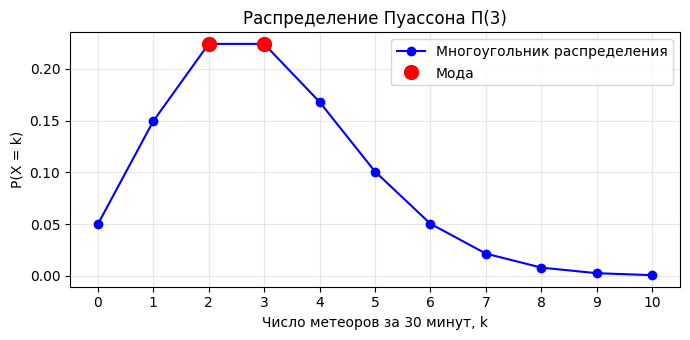

In [34]:
polygon(X, probabilities, mode_p, 'Число метеоров за 30 минут, k', 'Распределение Пуассона Π(3)')

## 3. Геометрический закон распределения
---
>**Условие.** Студент пытается дозвониться в деканат. Каждая попытка независимо от остальных заканчивается успехом с вероятностью $0.25$, и студент звонит до первого успеха. Случайная величина $X$ - номер попытки, на которой удалось дозвониться.

**Решение.** Испытания независимы, вероятность успеха в каждом $p = 0.25$, считаем число испытаний до первого успеха включительно, значит:

$$P(X = k) = q^{k - 1} p = 0.75^{k - 1} \cdot 0.25.$$
Значений бесконечно много, поэтому в таблицу запишем значения $k = 1, \dots, 12$.

In [36]:
p_g = 0.25
X = np.arange(1, 13)

geom_dist = geom(p_g)
probabilities = geom_dist.pmf(X)

print(f"Сумма вероятностей в таблице: {probabilities.sum():.4f}")
print(f"Вероятность остальных значений P(X > 12) = {geom_dist.sf(12):.4f}")
pd.DataFrame(probabilities.reshape(1, -1), columns=X, index=['p'])

Сумма вероятностей в таблице: 0.9683
Вероятность остальных значений P(X > 12) = 0.0317


,1,2,3,4,5,6,7,8,9,10,11,12
p,0.2500,0.1875,0.1406,0.1055,0.0791,0.0593,0.0445,0.0334,0.0250,0.0188,0.0141,0.0106


In [37]:
q_g = 1 - p_g
mode_g = X[np.isclose(probabilities, probabilities.max())].tolist()

print(f"Математическое ожидание: M(X) = 1/p = {1 / p_g:.4f}")
print(f"Дисперсия: D(X) = q/p^2 = {q_g / p_g ** 2:.4f}")
print(f"Среднее квадратическое отклонение: σ(X) = √q/p = {np.sqrt(q_g) / p_g:.4f}")
print(f"Мода: Mo(X) = {mode_g}")
print(f"\nПроверка через scipy: M = {geom_dist.mean():.4f}, D = {geom_dist.var():.4f}, σ = {geom_dist.std():.4f}")

Математическое ожидание: M(X) = 1/p = 4.0000
Дисперсия: D(X) = q/p^2 = 12.0000
Среднее квадратическое отклонение: σ(X) = √q/p = 3.4641
Мода: Mo(X) = [1]

Проверка через scipy: M = 4.0000, D = 12.0000, σ = 3.4641


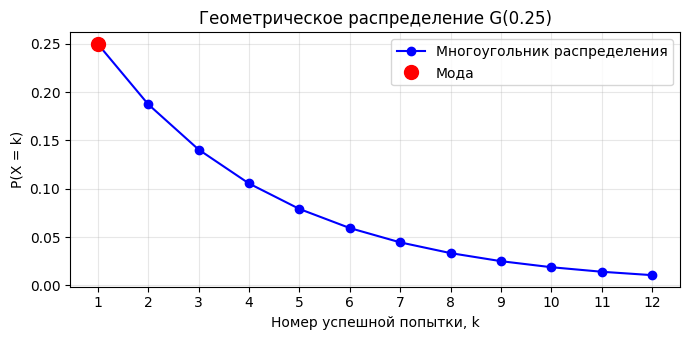

In [38]:
polygon(X, probabilities, mode_g, 'Номер успешной попытки, k', 'Геометрическое распределение G(0.25)')

## 4. Гипергеометрический закон распределения
---
>**Условие.** В коробке $25$ внешне одинаковых конфет, из них $9$ с вишнёвой начинкой, остальные с орехами. Наугад (без возвращения) берут $6$ конфет. Случайная величина $X$ - число конфет с вишнёвой начинкой среди выбранных.

**Решение.** $N = 25$ элементов, из них $K = 9$ «особых», объём выборки $n = 6$, значит:

$$P(X = k) = \frac{C_{9}^k \cdot C_{16}^{6 - k}}{C_{25}^6}.$$


In [39]:
N, K, n_draw = 25, 9, 6
X = np.arange(0, n_draw + 1)

hyper_dist = hypergeom(M=N, n=K, N=n_draw)  # в scipy: M - всего элементов, n - особых, N - объём выборки
probabilities = hyper_dist.pmf(X)

print(f"Сумма вероятностей: {probabilities.sum():.4f}")
pd.DataFrame(probabilities.reshape(1, -1), columns=X, index=['p'])

Сумма вероятностей: 1.0000


,0,1,2,3,4,5,6
p,0.0452,0.2220,0.3700,0.2656,0.0854,0.0114,0.0005


In [40]:
M = n_draw * K / N
D = n_draw * K / N * (1 - K / N) * (N - n_draw) / (N - 1)
mode_h = X[np.isclose(probabilities, probabilities.max())].tolist()

print(f"Математическое ожидание: M(X) = n*K/N = {M:.4f}")
print(f"Дисперсия: D(X) = {D:.4f}")
print(f"Среднее квадратическое отклонение: σ(X) = {np.sqrt(D):.4f}")
print(f"Мода: Mo(X) = {mode_h}  (по формуле [(n+1)(K+1)/(N+2)] = {int((n_draw + 1) * (K + 1) / (N + 2))})")
print(f"\nПроверка через scipy: M = {hyper_dist.mean():.4f}, D = {hyper_dist.var():.4f}, σ = {hyper_dist.std():.4f}")

Математическое ожидание: M(X) = n*K/N = 2.1600
Дисперсия: D(X) = 1.0944
Среднее квадратическое отклонение: σ(X) = 1.0461
Мода: Mo(X) = [2]  (по формуле [(n+1)(K+1)/(N+2)] = 2)

Проверка через scipy: M = 2.1600, D = 1.0944, σ = 1.0461


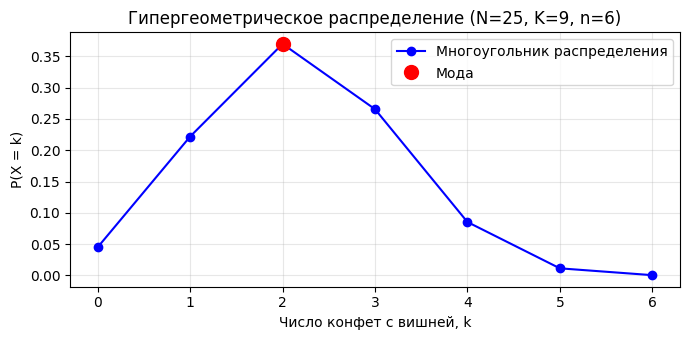

In [30]:
polygon(X, probabilities, mode_h, 'Число конфет с вишней, k', 'Гипергеометрическое распределение (N=25, K=9, n=6)')

## Сводная таблица
---

In [41]:
dists = [binom_dist, poisson_dist, geom_dist, hyper_dist]
summary = pd.DataFrame({
    'M(X)': [d.mean() for d in dists],
    'D(X)': [d.var() for d in dists],
    'σ(X)': [d.std() for d in dists],
    'Mo(X)': [', '.join(map(str, m)) for m in (mode_b, mode_p, mode_g, mode_h)]
}, index=['Биномиальное', 'Пуассон', 'Геометрическое', 'Гипергеометрическое'])
summary

,M(X),D(X),σ(X),Mo(X)
Биномиальное распределение,2.4000,1.6800,1.2961,2
Распределение Пуассона,3.0000,3.0000,1.7321,"2, 3"
Геометрическое распределение,4.0000,12.0000,3.4641,1
Гипергеометрическое распределение,2.1600,1.0944,1.0461,2
